# Flood Mapping with Sentinel-1 Polarimetric SAR — 1. Change Detection

Step-by-step change detection for the paper:

> Isundwa et al., *Analytical Optimization of Polarimetric Change Detectors for
> Mapping Open and Grassland Flooding Using Sentinel-1. Case of Rupununi, Guyana.*
> IEEE JSTARS, 2026.

This notebook loads a pair of dual-pol SAR acquisitions (SNAP-exported ENVI
covariance elements), applies speckle filtering, and computes a bank of
polarimetric change detectors. The **accuracy assessment** lives in a separate
notebook (`02_accuracy_assessment.ipynb`).

**Note on the environment:** the per-pixel loop uses single-matrix LAPACK calls
(`np.linalg.eigh`, `scipy.linalg.eig`, `inv`). Batched `np.linalg` is avoided
because some local BLAS builds crash on stacked arrays.

## 1. Imports

In [1]:
import os
import time
import numpy as np
from scipy import signal
import scipy.linalg as ln
import matplotlib.pyplot as plt

try:
    from tqdm import tqdm   
except ImportError:
    def tqdm(x, **k):
        return x

## 2. Reading the data (ENVI `.hdr` / `.img`)

A minimal ENVI reader — no `spectral` dependency. It parses the header for
`samples`, `lines`, `data type` and `byte order`, then loads the binary `.img`.
Each acquisition is stored as the covariance elements `C11`, `C22`, `C12`
(`C12` = `C12_real` + i·`C12_imag`).

In [2]:
# ENVI data type code -> numpy base dtype
_ENVI_DTYPE = {
    1: 'u1', 2: 'i2', 3: 'i4', 4: 'f4', 5: 'f8',
    6: 'c8', 9: 'c16', 12: 'u2', 13: 'u4', 14: 'i8', 15: 'u8',
}


def _parse_envi_header(hdr_path):
    """Parse the fields we need from an ENVI .hdr text file."""
    fields = {}
    with open(hdr_path, 'r') as f:
        for line in f:
            if '=' in line:
                k, v = line.split('=', 1)
                fields[k.strip().lower()] = v.strip()
    samples = int(fields['samples'])
    lines = int(fields['lines'])
    dcode = int(fields['data type'])
    border = int(fields.get('byte order', 0))
    base = _ENVI_DTYPE[dcode]
    dtype = np.dtype(('>' if border == 1 else '<') + base)   # 1 = big-endian
    return samples, lines, dtype


def Open_ENVI_Image(filename):
    """Open an ENVI binary image. `filename` is the path WITHOUT extension."""
    samples, lines, dtype = _parse_envi_header(filename + '.hdr')
    with open(filename + '.img', 'rb') as f:
        img = np.fromfile(f, dtype=dtype)

    img = img.reshape((samples, lines), order='F').astype(dtype)
    return img


def Load_One_Date_Dual(path, date):
    """Load the covariance elements (C11, C22, C12 complex) for one date."""
    C11 = Open_ENVI_Image(path + 'C11_' + date)
    C22 = Open_ENVI_Image(path + 'C22_' + date)
    C12_real = Open_ENVI_Image(path + 'C12_real_' + date)
    C12_imag = Open_ENVI_Image(path + 'C12_imag_' + date)
    C12 = C12_real + 1j * C12_imag
    del C12_real, C12_imag
    return C11, C22, C12

## 3. Speckle filtering (boxcar multilook)

A simple boxcar average of the covariance elements reduces speckle before
change detection.

In [3]:
def Boxcar_Pol_filter_Dual(C11, C22, C12, win=(7, 7)):
    """Boxcar multilooking of the covariance elements."""
    w1, w2 = int(win[0]), int(win[1])
    kernel = np.ones((w1, w2), np.float32) / (w1 * w2)
    opt = dict(mode='same', boundary='fill', fillvalue=0)
    C11f = signal.convolve2d(C11, kernel, **opt)
    C22f = signal.convolve2d(C22, kernel, **opt)
    C12f = signal.convolve2d(C12, kernel, **opt)   
    return C11f, C22f, C12f

## 4. The detector bank

For every pixel we build the two 2×2 Hermitian covariance matrices
(`Ta` = C2 = during flood, `Tb` = C1 = reference) and compute:

| Detector | Meaning |
|---|---|
| `Dif1`, `Dif2` | OPDiff — max / min eigenvalue of `C2 − C1` |
| `Alpha1`, `Alpha2` | eigenvector angles of the difference |
| `Rat1`, `Rat2` | OPRatio — eigenvalues of `C1⁻¹ C2` |
| `RatDif` | Model 4 (mixed) — `Rat2² · Dif1` (headline detector) |
| `MonU1`, `MonU2` | Model 1 (monomial unitary) |
| `Lin1`, `Lin2` | Model 3 (linear) |
| `RatVV`, `RatVH` | simple backscatter ratios |
| `Wishart`, `Trace` | reference statistics |

Returns a **dictionary** of detector-name → 2-D array.

In [4]:
def compute_change_detectors(C11_a, C22_a, C12_a,
                             C11_b, C22_b, C12_b,
                             eps=1e-6, progress=True):
    """Compute all change detectors for one image pair, pixel by pixel.

    _a = image 2 (during flood / C2);  _b = image 1 (reference / C1).
    Returns dict of float32 (H, W) arrays, one per detector.
    """
    dima, dimr = C11_a.shape

    Dif1 = np.zeros((dima, dimr), np.float32)
    Dif2 = np.zeros((dima, dimr), np.float32)
    Alpha1 = np.zeros((dima, dimr), np.float32)
    Alpha2 = np.zeros((dima, dimr), np.float32)
    Rat1 = np.zeros((dima, dimr), np.float32)
    Rat2 = np.zeros((dima, dimr), np.float32)
    RatDif = np.zeros((dima, dimr), np.float32)
    MonU1 = np.zeros((dima, dimr), np.float32)
    MonU2 = np.zeros((dima, dimr), np.float32)
    Lin1 = np.zeros((dima, dimr), np.float32)
    Lin2 = np.zeros((dima, dimr), np.float32)
    Wishart = np.zeros((dima, dimr), np.float32)
    Trace = np.zeros((dima, dimr), np.float32)

    Ta = np.zeros((2, 2), dtype=np.complex128)
    Tb = np.zeros((2, 2), dtype=np.complex128)

    rows = tqdm(range(dima)) if progress else range(dima)
    for i in rows:
        for ii in range(dimr):
            # Build the two 2x2 Hermitian covariance matrices
            Ta[0, 0] = C11_a[i, ii] + eps
            Ta[1, 1] = C22_a[i, ii] + eps
            Ta[0, 1] = C12_a[i, ii]
            Ta[1, 0] = np.conj(Ta[0, 1])
            Tb[0, 0] = C11_b[i, ii] + eps
            Tb[1, 1] = C22_b[i, ii] + eps
            Tb[0, 1] = C12_b[i, ii]
            Tb[1, 0] = np.conj(Tb[0, 1])

            # ---- OPDiff : B = C2 - C1 (Hermitian) ----
            d2, v2 = np.linalg.eigh(Ta - Tb)        # ascending reals
            Dif1[i, ii] = d2[1]                     # max power difference
            Dif2[i, ii] = d2[0]                     # min power difference
            Alpha1[i, ii] = np.arccos(np.abs(v2[0, 1]))
            Alpha2[i, ii] = np.arccos(np.abs(v2[0, 0]))

            # ---- OPRatio : A = C1^{-1} C2 ----
            A = np.linalg.inv(Tb) @ Ta
            [d1, v1] = ln.eig(A)
            # d1 = ln.eig(A)[0]
            d1 = np.abs(d1)
            Rat1[i, ii] = np.max(d1)               # largest |eigenvalue|
            Rat2[i, ii] = 1.0 / np.min(d1)         # reciprocal of smallest
            Trace[i, ii] = np.real(A[0, 0] + A[1, 1])

            # ---- Model 4 (mixed) : headline detector  Rat2^2 * Dif1 ----
            RatDif[i, ii] = Rat2[i, ii] ** 2 * Dif1[i, ii]

            # ---- Model 1 (monomial unitary) : whiten C1 with C2 ----
            wa, va = np.linalg.eigh(Ta)             # C2 Hermitian PD
            wa = np.clip(wa, 1e-10, None)
            Ta_is = (va * (1.0 / np.sqrt(wa))) @ va.conj().T   # C2^{-1/2}
            Tm_u = Ta_is @ Tb @ Ta_is
            lam_u = np.linalg.eigvalsh(Tm_u)
            m1 = lam_u * (lam_u - 1.0)
            MonU1[i, ii] = np.max(m1)
            MonU2[i, ii] = np.min(m1)

            # ---- Model 3 (linear) : faithful to original (ELEMENT-WISE sqrt) ----
            Ta_sqrt = np.sqrt(Ta)                   # element-wise, as original code
            Tm_l = Ta_sqrt @ Tb @ Ta_sqrt
            dl = ln.eig(Tm_l)[0]
            Lin1[i, ii] = np.real(dl[1])
            Lin2[i, ii] = np.real(dl[0])

            # ---- Wishart ----
            detA = Ta[0, 0] * Ta[1, 1] - Ta[0, 1] * Ta[1, 0]
            detB = Tb[0, 0] * Tb[1, 1] - Tb[0, 1] * Tb[1, 0]
            Tavg = (Ta + Tb) / 2.0
            detAvg = Tavg[0, 0] * Tavg[1, 1] - Tavg[0, 1] * Tavg[1, 0]
            Wishart[i, ii] = np.abs(detA) * np.abs(detB) / (np.abs(detAvg) ** 2 + eps)

    # ---- Simple backscatter ratios (vectorised, no LAPACK) ----
    RatVV = ((C11_a + eps) / (C11_b + eps)).astype(np.float32)
    RatVH = ((C22_a + eps) / (C22_b + eps)).astype(np.float32)

    return {
        'Dif1': Dif1, 'Dif2': Dif2,
        'Alpha1': Alpha1, 'Alpha2': Alpha2,
        'Rat1': Rat1, 'Rat2': Rat2,
        'RatDif': RatDif,
        'MonU1': MonU1, 'MonU2': MonU2,
        'Lin1': Lin1, 'Lin2': Lin2,
        'RatVV': RatVV, 'RatVH': RatVH,
        'Wishart': Wishart, 'Trace': Trace,
    }

## 5. Configuration

Point `DATA_ROOT` at the folder that holds one sub-folder per date. Set `CROP`
to a small integer for a quick test (centre window), or `None` to process the
full scene (the per-pixel loop on a full scene can take tens of minutes).

In [5]:
DATA_ROOT = r'..\data'

# --- choose the reference image -------------------------------------------
USE_MEAN_REF = True           # True = March mean (Ref_03); False = single date

if USE_MEAN_REF:
    DATE_REF        = 'Ref_03'     # folder written by build_reference.py
    REF_PREFILTERED = False         # mean is already boxcar-filtered -> don't filter again
else:
    DATE_REF        = '20170329'   # single reference acquisition (raw)
    REF_PREFILTERED = False        # raw single image -> needs filtering
# -------------------------------------------------------------------------

DATE_TEST = '20170703'
WIN  = (7, 7)     # boxcar window
CROP = None       # centre crop size in pixels; None = full scene

## 6. Load and filter the image pair

Loading reference Ref_03 ...
Loading test      20170703 ...
Full scene size: (6704, 2734)
Boxcar filtering ...
Done.


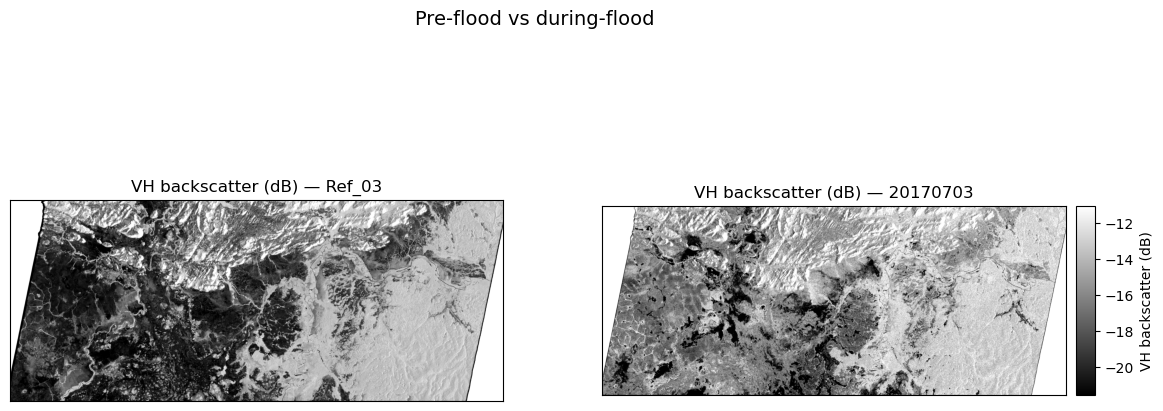

In [6]:
ref_dir  = os.path.join(DATA_ROOT, DATE_REF) + os.sep
test_dir = os.path.join(DATA_ROOT, DATE_TEST) + os.sep

print(f'Loading reference {DATE_REF} ...')
C11b, C22b, C12b = Load_One_Date_Dual(ref_dir, DATE_REF)
print(f'Loading test      {DATE_TEST} ...')
C11a, C22a, C12a = Load_One_Date_Dual(test_dir, DATE_TEST)
print('Full scene size:', C11a.shape)

if CROP is not None:
    r0 = C11a.shape[0] // 2
    c0 = C11a.shape[1] // 2
    sl = (slice(r0, r0 + CROP), slice(c0, c0 + CROP))
    C11b, C22b, C12b = C11b[sl], C22b[sl], C12b[sl]
    C11a, C22a, C12a = C11a[sl], C22a[sl], C12a[sl]
    print('Cropped to:', C11a.shape)

print('Boxcar filtering ...')
if not REF_PREFILTERED:                      # skip for the pre-filtered mean
    C11b, C22b, C12b = Boxcar_Pol_filter_Dual(C11b, C22b, C12b, WIN)
C11a, C22a, C12a = Boxcar_Pol_filter_Dual(C11a, C22a, C12a, WIN)
print('Done.')


from mpl_toolkits.axes_grid1 import make_axes_locatable

cmap = plt.cm.gray.copy()
cmap.set_bad('white')

# dB + validity for each scene
def to_db(C):
    arr = np.abs(C.T)
    valid = np.isfinite(arr) & (arr > 0)
    return 10 * np.log10(arr + 1e-12), valid

disp_b, valid_b = to_db(C22b)
disp_a, valid_a = to_db(C22a)

# ONE stretch from both scenes' valid pixels -> both panels on the same scale
both = np.concatenate([disp_b[valid_b], disp_a[valid_a]])
vmin, vmax = np.nanpercentile(both, (2, 98))

fig, ax = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for a, disp, valid, date in [(ax[0], disp_b, valid_b, DATE_REF),
                             (ax[1], disp_a, valid_a, DATE_TEST)]:
    m = np.ma.masked_where(~valid, disp)
    im = a.imshow(m, cmap=cmap, vmin=vmin, vmax=vmax, aspect='equal')
    a.set_title(f'VH backscatter (dB) — {date}')
    a.set_xticks([]); a.set_yticks([])

# single colorbar, matched to the right image's height
cax = make_axes_locatable(ax[1]).append_axes('right', size='4%', pad=0.1)
fig.colorbar(im, cax=cax).set_label('VH backscatter (dB)')

fig.suptitle('Pre-flood vs during-flood', fontsize=14)
plt.show()

## 7. Run the change detection

In [7]:
import glob

RESULTS_DIR = os.path.join('..', 'results')
REF_TAG = DATE_REF.replace('Ref_', '') if DATE_REF.startswith('Ref_') else DATE_REF
FORCE_RECOMPUTE = False                      # set True to recompute even if outputs exist

suffix = f'_{DATE_TEST}_{REF_TAG}.npy'
existing = sorted(glob.glob(os.path.join(RESULTS_DIR, f'*{suffix}')))

if existing and not FORCE_RECOMPUTE:
    print(f'Found {len(existing)} saved detectors for {DATE_TEST} (ref {REF_TAG}) '
          f'-> loading, skipping change detection')
    det = {os.path.basename(p)[:-len(suffix)]: np.load(p) for p in existing}
else:
    print('Running change detection ...')
    t0 = time.time()
    det = compute_change_detectors(C11a, C22a, C12a, C11b, C22b, C12b)
    print(f'Computed {len(det)} detectors in {time.time() - t0:.1f} s')

print('\n--- detector summary (min / max / mean) ---')
for k, v in det.items():
    print(f'  {k:8s} {np.nanmin(v): .4g}  ..  {np.nanmax(v): .4g}  (mean {np.nanmean(v): .4g})')

Running change detection ...


100%|██████████| 6704/6704 [1:02:33<00:00,  1.79it/s]


Computed 15 detectors in 3753.5 s

--- detector summary (min / max / mean) ---
  Dif1     -0.1722  ..   25.29  (mean  0.03725)
  Dif2     -1.289  ..   0.3355  (mean  0.001816)
  Alpha1    2.518e-05  ..   1.571  (mean  0.5159)
  Alpha2    0  ..   1.571  (mean  1.055)
  Rat1      1.119e-05  ..   431.2  (mean  1.734)
  Rat2      0.1202  ..   3.926e+05  (mean  23.08)
  RatDif   -1.377e+10  ..   13.1  (mean -3.848e+04)
  MonU1    -0.25  ..   1.541e+11  (mean  1.134e+06)
  MonU2    -0.25  ..   7.99e+09  (mean  7.132e+04)
  Lin1      1e-12  ..   0.3526  (mean  0.0009796)
  Lin2      1e-12  ..   22.08  (mean  0.02621)
  RatVV     2.548e-06  ..   428.9  (mean  1.471)
  RatVH     1.118e-05  ..   9.33  (mean  1.522)
  Wishart   1e-18  ..   0.9999  (mean  0.6242)
  Trace     1.373e-05  ..   432.8  (mean  2.998)


## 8. Plot the detector results (before thresholding)

The dictionary below controls **which detectors are plotted**. Comment out any
line (or set it to `None`) to skip that detector. Each entry is
`'Name': dict(cmap=..., sym=...)` where `sym=True` centres the colour scale on
zero (useful for difference-type detectors).

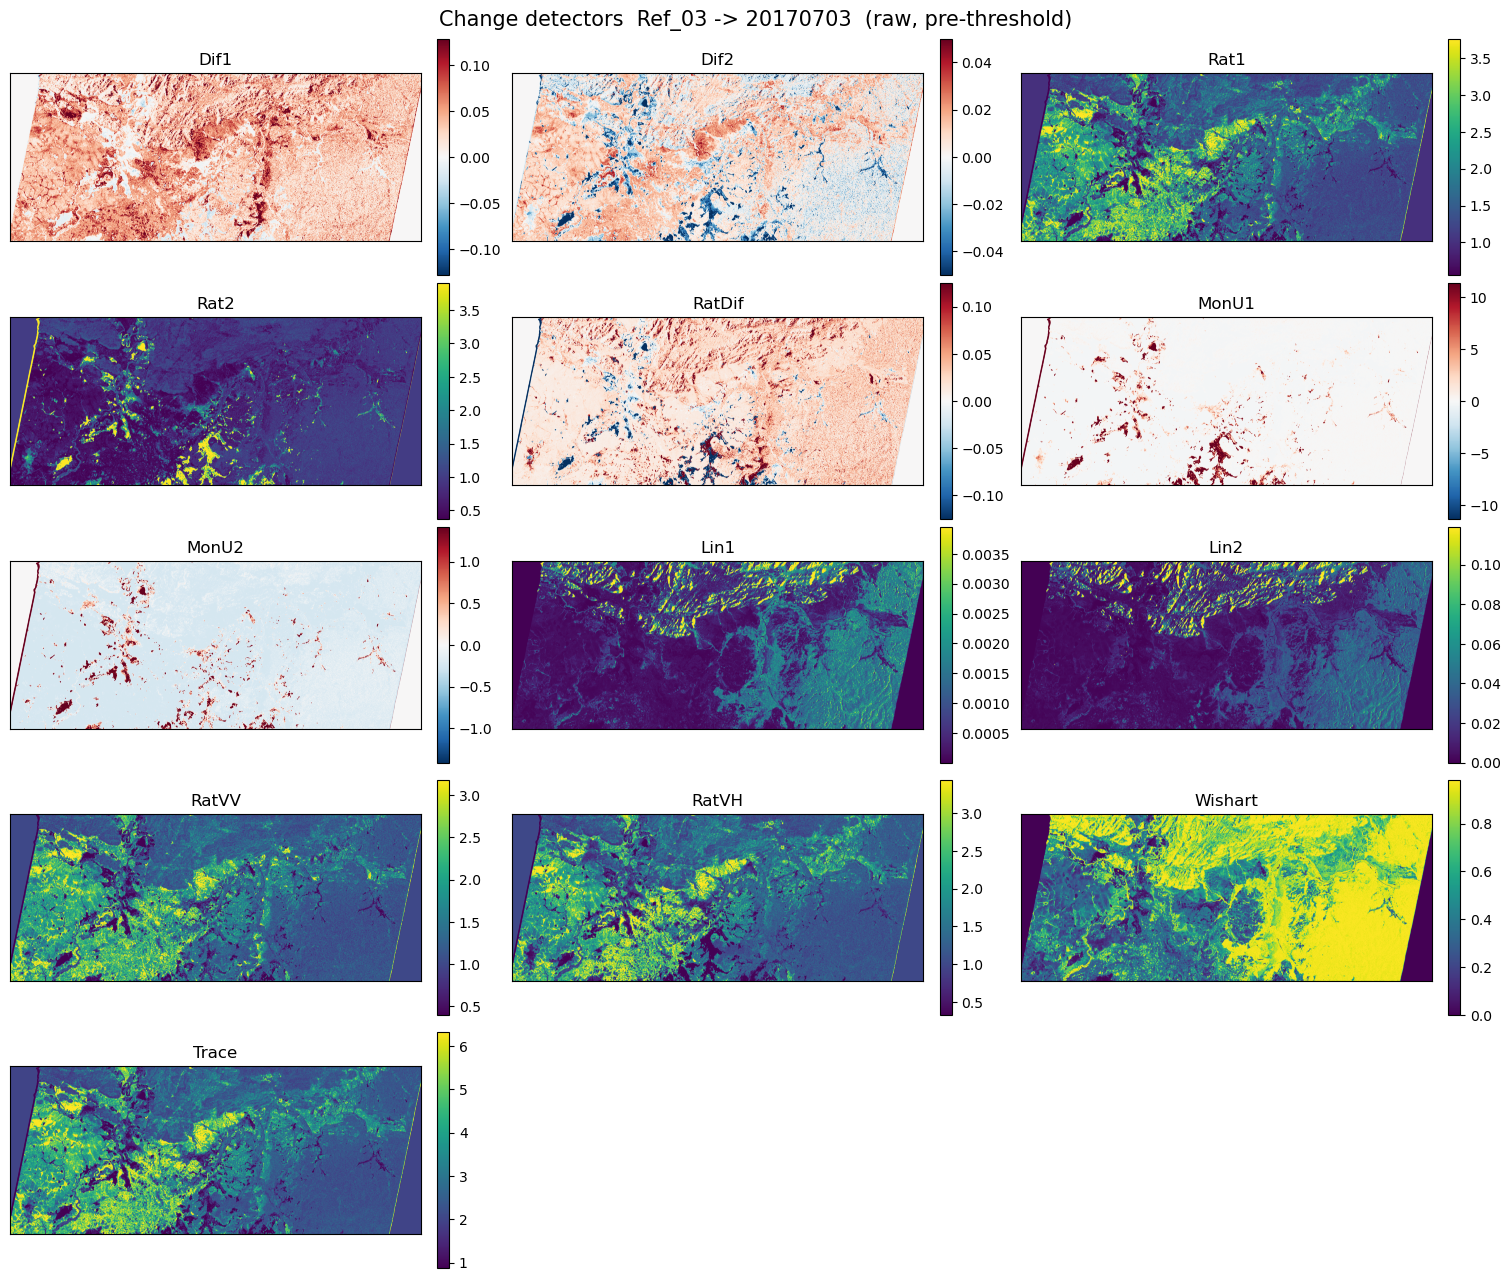

In [8]:
def plot_detectors(det, selection, ncols=3, pct=(2, 98), cell_w=5.0):
    """Show each selected detector as a map, square pixels, auto-sized to data shape."""
    names = [n for n in selection if selection[n] is not None and n in det]
    n = len(names)
    nrows = int(np.ceil(n / ncols))

    H, W = det[names[0]].T.shape            # data aspect (rows, cols)
    cell_h = cell_w * (H / W)               # match cell height to the image ratio

    fig, axes = plt.subplots(nrows, ncols,
                             figsize=(cell_w * ncols, cell_h * nrows + 0.5 * nrows),
                             constrained_layout=True)
    axes = np.atleast_1d(axes).ravel()
    for ax, name in zip(axes, names):
        opt = selection[name]
        data = det[name].T
        vmin, vmax = np.nanpercentile(data, pct)
        if opt.get('sym'):
            m = max(abs(vmin), abs(vmax))
            vmin, vmax = -m, m
        im = ax.imshow(data, cmap=opt.get('cmap', 'viridis'),
                       vmin=vmin, vmax=vmax, aspect='equal')   # square pixels
        ax.set_title(name, fontsize=12)
        ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    for ax in axes[n:]:
        ax.axis('off')
    fig.suptitle(f'Change detectors  {DATE_REF} -> {DATE_TEST}  (raw, pre-threshold)',
                 fontsize=15)
    return fig

PLOT_DETECTORS = {
    'Dif1':   dict(cmap='RdBu_r', sym=True),
    'Dif2':   dict(cmap='RdBu_r', sym=True),
    'Rat1':   dict(cmap='viridis', sym=False),
    'Rat2':   dict(cmap='viridis', sym=False),
    'RatDif': dict(cmap='RdBu_r', sym=True),
    'MonU1':  dict(cmap='RdBu_r', sym=True),
    'MonU2':  dict(cmap='RdBu_r', sym=True),
    'Lin1':   dict(cmap='viridis', sym=False),
    'Lin2':   dict(cmap='viridis', sym=False),
    'RatVV':  dict(cmap='viridis', sym=False),
    'RatVH':  dict(cmap='viridis', sym=False),
    'Wishart':dict(cmap='viridis', sym=False),
    'Trace':  dict(cmap='viridis', sym=False),
    # 'Alpha1': dict(cmap='twilight', sym=False),
    # 'Alpha2': dict(cmap='twilight', sym=False),
}

fig = plot_detectors(det, PLOT_DETECTORS)
plt.show()

## 9. Two-threshold flood classification (RatDif)

`RatDif` (= `Rat2² · Dif1`, the Model-4 detector) is **signed**, and the sign
separates the two flood types:

- **Open-water flood → negative** (backscatter drops: `Dif1` negative)
- **Flood under vegetation / grassland → positive** (double-bounce raises backscatter)
- **No change → near zero**

So a single threshold is not enough: we apply **two** thresholds — one negative
(`T_OPEN`) and one positive (`T_VEG`) — to map the two distinct floods and leave
a no-change band in between. The histogram on the right helps you place them.

Open-flood pixels:  335,193
Veg-flood pixels:   190,427


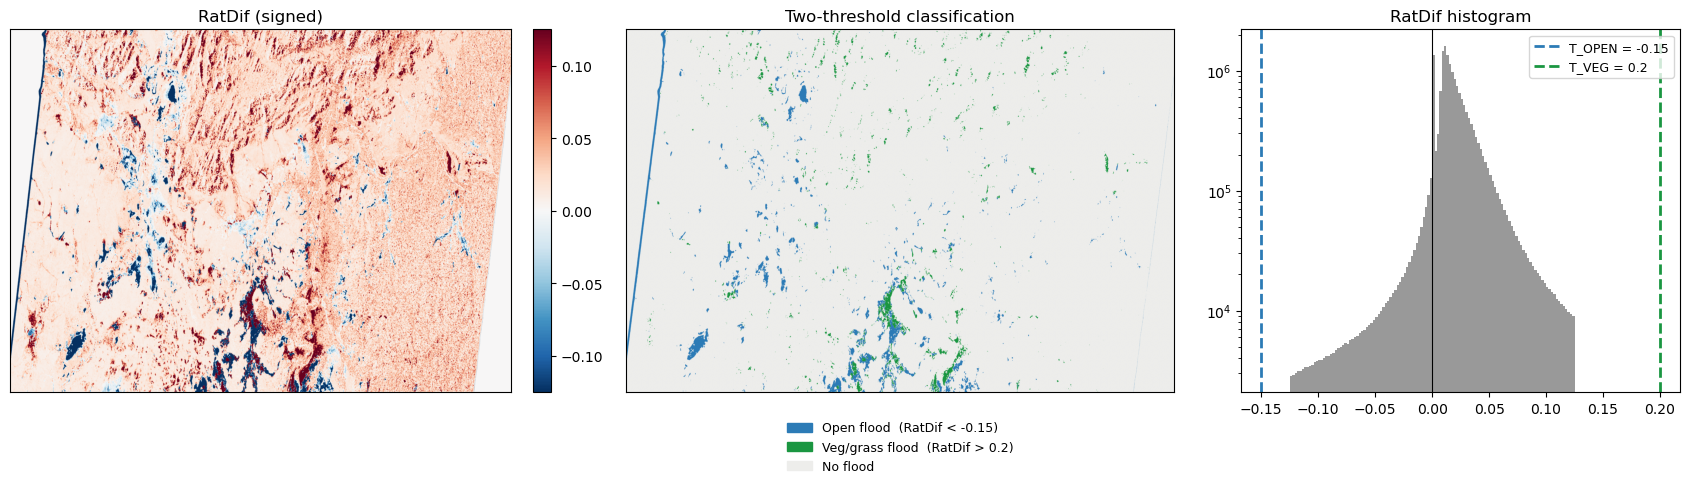

In [9]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch


def classify_dual_threshold(arr, t_open, t_veg):
    """0 = no-flood, 1 = open flood (arr < t_open), 2 = veg/grass flood (arr > t_veg)."""
    cls = np.zeros(arr.shape, dtype=np.uint8)
    cls[arr < t_open] = 1
    cls[arr > t_veg] = 2
    return cls


def plot_dual_threshold(arr, t_open, t_veg, name='RatDif', pct=(2, 98)):
    """Show the signed detector, the two-threshold classification, and a histogram."""
    disp = np.asarray(arr).T          
    cls = classify_dual_threshold(disp, t_open, t_veg)
    vmin, vmax = np.nanpercentile(disp, pct)
    m = max(abs(vmin), abs(vmax))

    fig, ax = plt.subplots(1, 3, figsize=(17, 5),
                           gridspec_kw={'width_ratios': [1, 1, 0.8]})

    im = ax[0].imshow(disp, cmap='RdBu_r', vmin=-m, vmax=m, aspect='auto')
    ax[0].set_title(f'{name} (signed)'); ax[0].set_xticks([]); ax[0].set_yticks([])
    fig.colorbar(im, ax=ax[0], fraction=0.046, pad=0.04)

    cmap = ListedColormap(['#ededeb', '#2c7bb6', '#1a9641'])
    ax[1].imshow(cls, cmap=cmap, vmin=0, vmax=2, aspect='auto')
    ax[1].set_title('Two-threshold classification')
    ax[1].set_xticks([]); ax[1].set_yticks([])
    handles = [Patch(color='#2c7bb6', label=f'Open flood  ({name} < {t_open:g})'),
               Patch(color='#1a9641', label=f'Veg/grass flood  ({name} > {t_veg:g})'),
               Patch(color='#ededeb', label='No flood')]
    ax[1].legend(handles=handles, loc='upper center',
                 bbox_to_anchor=(0.5, -0.05), ncol=1, fontsize=9, frameon=False)

    vals = disp[np.isfinite(disp)].ravel()
    ax[2].hist(vals, bins=120, range=(-m, m), color='0.6')
    ax[2].axvline(t_open, color='#2c7bb6', ls='--', lw=2, label=f'T_OPEN = {t_open:g}')
    ax[2].axvline(t_veg, color='#1a9641', ls='--', lw=2, label=f'T_VEG = {t_veg:g}')
    ax[2].axvline(0, color='k', lw=0.8)
    ax[2].set_title(f'{name} histogram'); ax[2].legend(fontsize=9)
    ax[2].set_yscale('log')

    counts = {1: int((cls == 1).sum()), 2: int((cls == 2).sum())}
    print(f'Open-flood pixels:  {counts[1]:,}')
    print(f'Veg-flood pixels:   {counts[2]:,}')
    fig.tight_layout()
    return fig, cls


# Thresholds: tune using the histogram. Defaults = a fraction of the robust scale,
# symmetric about zero. 
ratdif = det['RatDif']
k = 0.2# * np.nanstd(ratdif)
T_OPEN = -0.15     # below this (negative) -> open flood
T_VEG = +k      # above this (positive) -> vegetation / grassland flood

fig, ratdif_class = plot_dual_threshold(ratdif, T_OPEN, T_VEG)
plt.show()

## 10. Save the detector outputs

Write every detector to the `results/` folder as `<name>_<date>.npy` so the
**accuracy-assessment notebook** can load them without recomputing. A small
`manifest_<date>.json` is written alongside for reference.

Set `transpose=True` if your reference masks use the opposite (lines, samples)
orientation — then the saved arrays already match the masks and you can drop the
`transpose=True` argument in the accuracy notebook.

`save_detectors` is defined below so this notebook stays self-contained; it is
also available in `change_detection.py`.

In [10]:
def save_detectors(det, results_dir, date, ref, transpose=False):
    """Save each detector as <name>_<date>_<ref>.npy (+ manifest). `ref` tags the reference image."""
    import json
    results_dir = str(results_dir)
    os.makedirs(results_dir, exist_ok=True)
    for name, arr in det.items():
        a = np.asarray(arr)
        if transpose:
            a = a.T
        np.save(os.path.join(results_dir, f'{name}_{date}_{ref}.npy'), a.astype(np.float32))
    first = np.asarray(next(iter(det.values())))
    shape = list((first.T if transpose else first).shape)
    manifest = {'date': date, 'ref': ref, 'detectors': list(det.keys()),
                'shape': shape, 'transpose': transpose}
    with open(os.path.join(results_dir, f'manifest_{date}_{ref}.json'), 'w') as f:
        json.dump(manifest, f, indent=2)
    print(f'Saved {len(det)} detectors for {date} (ref {ref}) -> {results_dir}')
    return results_dir


RESULTS_DIR = os.path.join('..', 'results')

# derive the ref tag: 'Ref_03' -> '03', else use the date itself ('20170329')
REF_TAG = DATE_REF.replace('Ref_', '') if DATE_REF.startswith('Ref_') else DATE_REF

save_detectors(det, RESULTS_DIR, DATE_TEST, REF_TAG, transpose=False)
print('Results dir (absolute):', os.path.abspath(RESULTS_DIR))

Saved 15 detectors for 20170703 (ref 03) -> ..\results
Results dir (absolute): D:\Flood_Mapping_tutorial\results
